# E-commerce customer churn prediction

A retention team can only contact about 10% of its customers. This notebook tries to answer one question: **which customers should they contact first?**

I use the Kaggle "E Commerce Dataset" (5,630 customers, about 17% churn). Download it, rename it `E_Commerce_Dataset.xlsx` and put it in `data/raw/`.

**How I kept the numbers honest**
1. I split the data first. The test set stays locked until Step 13.
2. Anything I learn from the data (medians, caps, oversampling) comes from training data only.
3. Identical rows stay on the same side of the split.
4. Every model has to beat a few simple baselines.
5. I use the test set once.

In [53]:
import os, json, itertools, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")

## Step 1. Load the data

In [54]:
DATA_PATH = "../data/raw/E_Commerce_Dataset.xlsx"   # change this if your file is somewhere else
df = pd.read_excel(DATA_PATH, sheet_name="E Comm")
print(df.shape)
df.head(3)

(5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28


## Step 2. A first look

Three quick checks: how many customers churn, which columns have gaps, and whether any customer shows up twice.

For the duplicate check I drop `CustomerID` first. Every ID is different, so with the ID left in, the answer is always "0 duplicates".

In [55]:
print("Churn rate:", round(df["Churn"].mean(), 3))
print()
missing = df.isna().sum()
print("Missing values:")
print(missing[missing > 0])
print()
print("Duplicate rows (ignoring CustomerID):", df.drop(columns="CustomerID").duplicated().sum())

Churn rate: 0.168

Missing values:
Tenure                         264
WarehouseToHome                251
HourSpendOnApp                 255
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
dtype: int64

Duplicate rows (ignoring CustomerID): 556


What I take from this:
- About 17% of customers churn. A model that says "nobody churns" is right 83% of the time, so accuracy tells us very little here.
- Seven columns are missing around 4-5% of their values. I fill them later, inside the pipeline.
- Duplicates matter. If a customer is in the training data and an identical copy sits in the test data, the model is being graded on something it has already seen.

## Step 3. Fix the labels

Some categories are the same thing written two ways: `Phone` and `Mobile Phone`, `CC` and `Credit Card`, `COD` and `Cash on Delivery`. That's a data entry problem, so I merge them by hand. The rule doesn't use the churn column, so it's safe to do before the split.

In [56]:
def clean(d):
    d = d.copy()
    d["PreferredLoginDevice"] = d["PreferredLoginDevice"].replace({"Phone": "Mobile Phone"})
    d["PreferredPaymentMode"] = d["PreferredPaymentMode"].replace({"CC": "Credit Card", "COD": "Cash on Delivery"})
    return d

print(clean(df)["PreferredPaymentMode"].value_counts())

PreferredPaymentMode
Debit Card          2314
Credit Card         1774
E wallet             614
Cash on Delivery     514
UPI                  414
Name: count, dtype: int64


## Step 4. Split first, and keep duplicates together

- `X_raw` holds the input columns. `y` holds the answer (churned or not).
- `groups` gives every set of identical rows the same number.
- `StratifiedGroupKFold` cuts the data into 5 slices. I take one slice as the test set. Identical rows never end up on both sides, and the churn rate stays about the same in both parts.

From here on I didn't touch the test set until Step 13.

In [57]:
X_raw = df.drop(columns=["CustomerID", "Churn"])
y = df["Churn"]
groups = pd.factorize(pd.util.hash_pandas_object(X_raw, index=False))[0]   # same row -> same number
X = clean(X_raw)

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, y_train, g_train = X.iloc[train_idx], y.iloc[train_idx], groups[train_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

print("train:", len(X_train), "| test:", len(X_test))
print("churn rate train / test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

train: 4504 | test: 1126
churn rate train / test: 0.168 0.169


## Step 5. Explore the training data

Only the training part. If I looked at the test set here, it could quietly shape my choices.

In [58]:
train = X_train.assign(Churn=y_train)

def churn_by(col):
    return train.groupby(col)["Churn"].agg(["mean", "count"]).round(3)

churn_by("PreferredPaymentMode")

,mean,count
PreferredPaymentMode,,
Cash on Delivery,0.259,410
Credit Card,0.140,1437
Debit Card,0.154,1827
E wallet,0.225,498
UPI,0.172,332


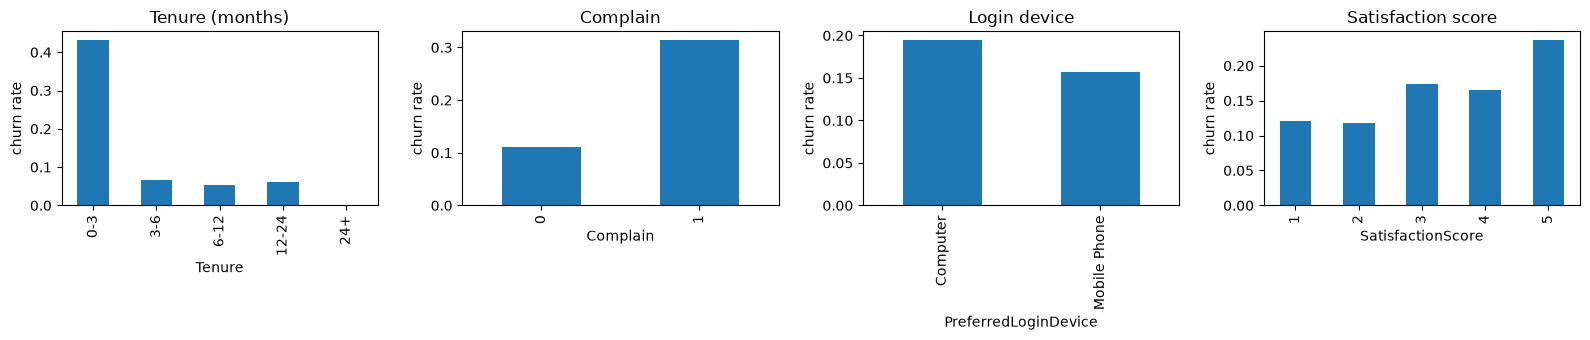

In [59]:
tenure_group = pd.cut(train["Tenure"], [-1, 3, 6, 12, 24, 100], labels=["0-3", "3-6", "6-12", "12-24", "24+"])
panels = [("Tenure (months)", tenure_group), ("Complain", train["Complain"]),
          ("Login device", train["PreferredLoginDevice"]), ("Satisfaction score", train["SatisfactionScore"])]

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, (title, col) in zip(axes, panels):
    train.groupby(col, observed=True)["Churn"].mean().plot.bar(ax=ax, title=title)
    ax.set_ylabel("churn rate")
plt.tight_layout()
plt.show()

Next, here's the churn rate inside every category. The red dashed line is the overall churn rate. I look at the bars that sit far from that line.

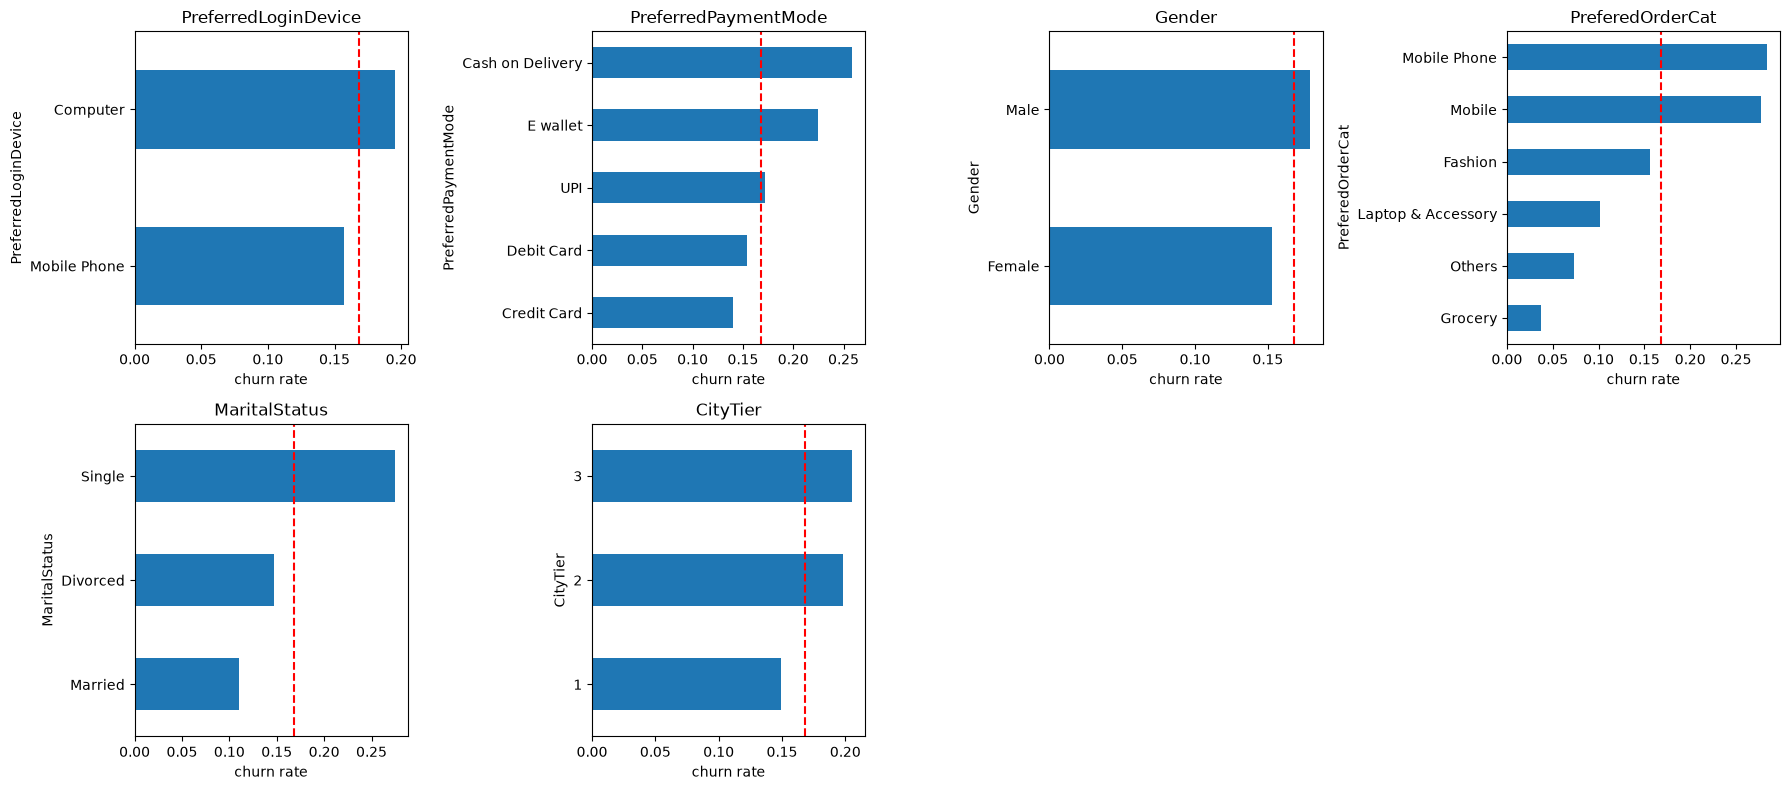

In [60]:
cat_cols = list(X_train.select_dtypes(exclude="number").columns) + ["CityTier"]
overall = train["Churn"].mean()

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), cat_cols):
    train.groupby(col)["Churn"].mean().sort_values().plot.barh(ax=ax, title=col)
    ax.axvline(overall, color="red", linestyle="--")
    ax.set_xlabel("churn rate")
for ax in axes.flatten()[len(cat_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

And here are the numeric columns. Each box shows where most customers sit. If the box for churners (1) sits apart from the box for stayers (0), that column separates the two groups, and I'll want to see if the model uses it.

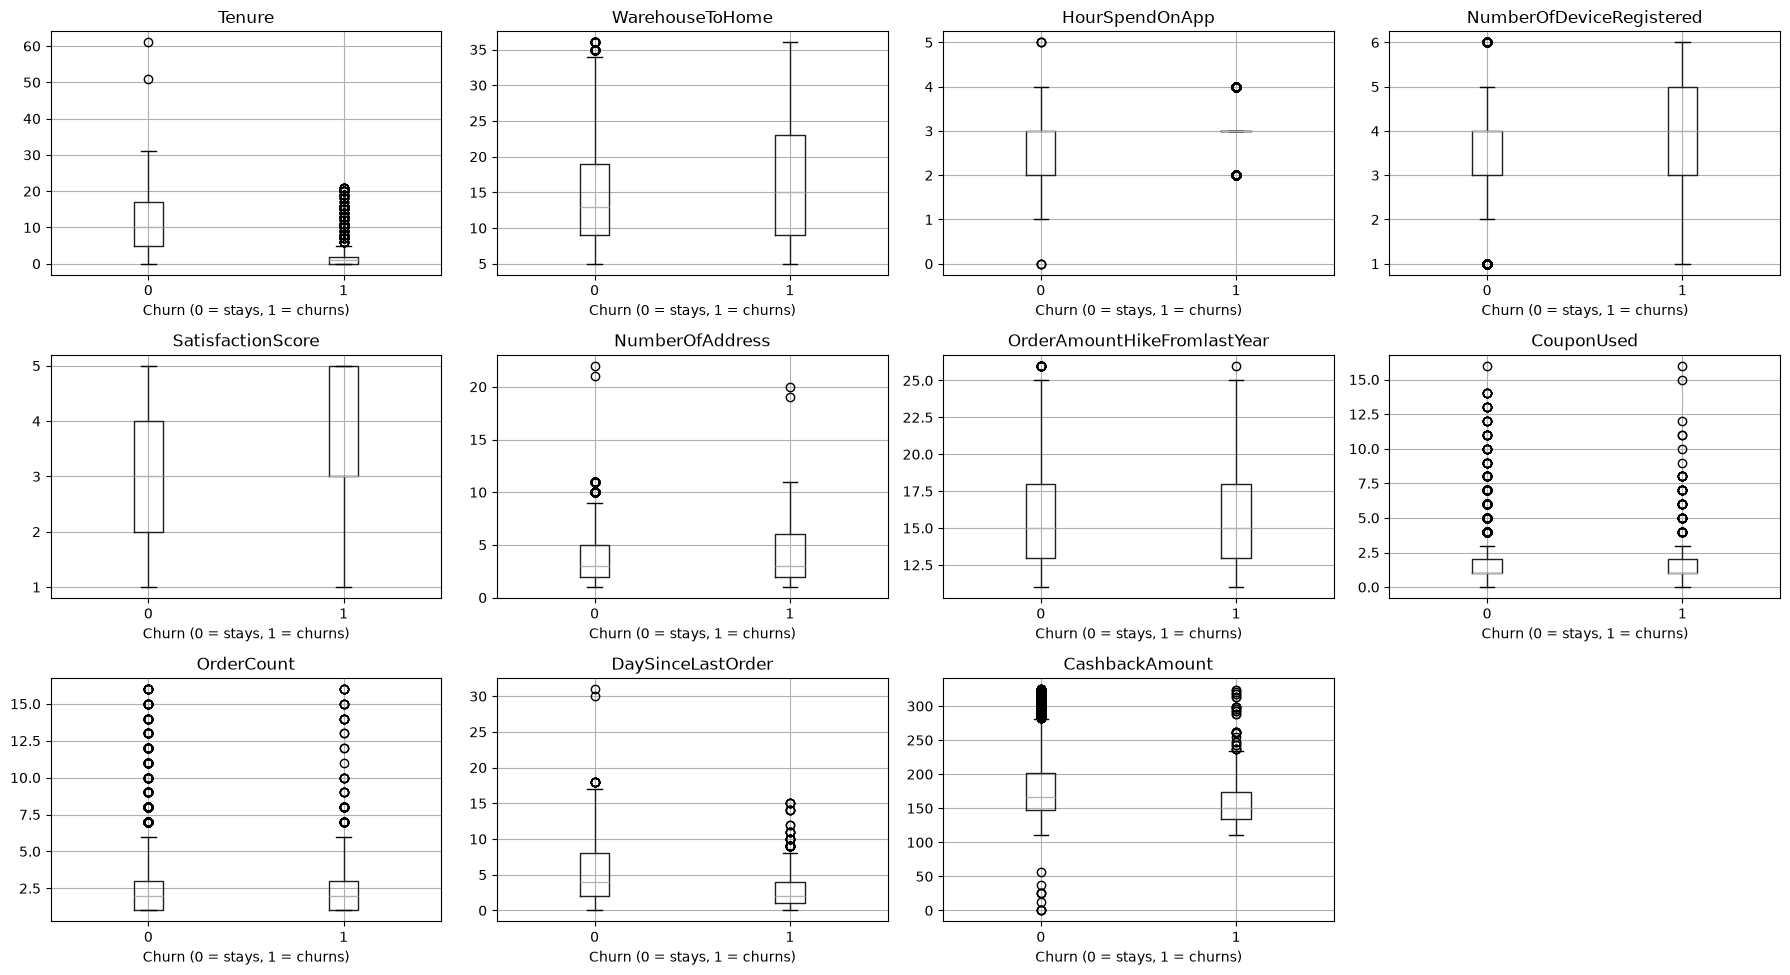

In [61]:
num_cols = [c for c in X_train.select_dtypes("number").columns if c not in ("CityTier", "Complain")]

fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.flatten(), num_cols):
    train.boxplot(column=col, by="Churn", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Churn (0 = stays, 1 = churns)")
for ax in axes.flatten()[len(num_cols):]:
    ax.axis("off")
plt.suptitle("")
plt.tight_layout()
plt.show()

I note the groups and columns that stand out, but I treat them as guesses. The later steps check whether the model really uses these patterns.

## Step 6. Two helper functions

- `top10` imagines the team contacting the 10% of customers the model ranks highest. It returns how many of all churners are on that list (`caught`) and how many people on the list really churn (`precision`).
- `report` puts the metrics for one model in one row.

Ties are broken at random, so a model that gives everyone the same score gets no unfair edge.

In [62]:
def top10(y_true, score):
    y_true = np.asarray(y_true)
    score = np.asarray(score) + np.random.default_rng(0).uniform(0, 1e-9, len(y_true))   # break ties
    k = int(len(y_true) * 0.10)
    top = np.argsort(-score)[:k]
    caught = y_true[top].sum()
    return caught / y_true.sum(), caught / k

def report(name, y_true, score):
    caught, precision = top10(y_true, score)
    return {"model": name,
            "ROC-AUC": roc_auc_score(y_true, score),
            "PR-AUC": average_precision_score(y_true, score),
            "caught top10%": caught,
            "precision top10%": precision}

## Step 7. The pipeline

A pipeline is a recipe that runs the same steps in the same order every time: fill gaps, (optionally) cap extreme values, turn text into numbers, (optionally) oversample, then train the model.

The point of a pipeline is that the recipe learns its numbers (like the median) from the training slice only. My first version calculated medians on all rows before the split, which let the test customers leak into training.

Three parts are optional, and I test them in Step 9:
- `add_features` adds one column, cashback per order.
- `Capper` limits extreme values with the IQR rule. The limits come from the training slice.
- `SMOTE` creates extra synthetic churners, in the training slice only.

In [63]:
def add_features(d):
    d = d.copy()
    d["Avg_cashbk_per_order"] = d["CashbackAmount"] / d["OrderCount"]
    return d


class Capper(BaseEstimator, TransformerMixin):
    # Caps extreme numbers. The limits are learned from training data only.
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        self.low_ = q1 - 1.5 * (q3 - q1)
        self.high_ = q3 + 1.5 * (q3 - q1)
        return self

    def transform(self, X):
        return pd.DataFrame(X).clip(self.low_, self.high_, axis=1).values


def build(model, data, scale=False, cap=False, smote=False):
    num_cols = data.select_dtypes("number").columns
    cat_cols = data.select_dtypes(exclude="number").columns

    num_steps = [("fill", SimpleImputer(strategy="median"))]
    if cap:
        num_steps.append(("cap", Capper()))
    if scale:
        num_steps.append(("scale", StandardScaler()))

    cat_steps = [("fill", SimpleImputer(strategy="most_frequent")),
                 ("onehot", OneHotEncoder(handle_unknown="ignore"))]

    prep = ColumnTransformer([("num", Pipeline(num_steps), num_cols),
                              ("cat", Pipeline(cat_steps), cat_cols)])
    steps = [("prep", prep)]
    if smote:
        steps.append(("smote", SMOTE(random_state=42)))
    steps.append(("model", model))
    return ImbPipeline(steps)

## Step 8. Baselines and models

I compare models with **cross-validation** on the training data. The training data is cut into 5 slices. The model learns from 4 and is tested on the 5th, five times over. It works like a practice quiz, so the real exam (the test set) stays hidden.

What's in the table:
- **Random list**: a dummy that ignores every feature. Its ROC-AUC should sit near 0.5. If it doesn't, something is wrong with my testing.
- **Rule: complained**: contact the people who complained.
- **Logistic Regression**: a simple model that's easy to read.
- **Random Forest** and **HistGradientBoosting**: stronger tree models.

In [64]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7)

def cv_scores(name, model, data=None, **options):
    data = X_train if data is None else data
    pipe = build(model, data, **options)
    p = cross_val_predict(pipe, data, y_train, cv=cv, groups=g_train, method="predict_proba")[:, 1]
    return report(name, y_train, p)

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
                            random_state=42, n_jobs=-1)
rows = [
    report("Rule: complained", y_train, X_train["Complain"].values.astype(float)),
    cv_scores("Random list", DummyClassifier(strategy="prior")),
    cv_scores("Logistic Regression", LogisticRegression(max_iter=2000, class_weight="balanced"), scale=True),
    cv_scores("Random Forest", rf),
    cv_scores("HistGradientBoosting", HistGradientBoostingClassifier(random_state=42)),
]
pd.DataFrame(rows).round(3)

,model,ROC-AUC,PR-AUC,caught top10%,precision top10%
0,Rule: complained,0.648,0.246,0.191,0.322
1,Random list,0.499,0.168,0.116,0.196
2,Logistic Regression,0.891,0.698,0.470,0.791
3,Random Forest,0.968,0.884,0.555,0.936
4,HistGradientBoosting,0.970,0.908,0.565,0.951


How to read it:
- `caught top10%` is the share of all churners that land inside the 10% list. No list can catch more than about 59% here, because 10% of customers is a smaller group than the churners.
- `precision top10%` is how many people on the list really churn.
- A gap smaller than 0.005 is probably noise.

## Step 9. Which extra steps help?

The Kaggle notebook I started from used a new feature, outlier capping and SMOTE. Instead of assuming they help, I test each one with the same model and the same cross-validation. A step only goes into the final model if it gives a clear gain.

In [65]:
X_feat = add_features(X_train)
hgb = lambda **kw: HistGradientBoostingClassifier(random_state=42, **kw)

setups = [
    ("A: base",               X_train, hgb(),                        {}),
    ("B: + new feature",      X_feat,  hgb(),                        {}),
    ("C: + capping",          X_feat,  hgb(),                        dict(cap=True)),
    ("D: + SMOTE",            X_feat,  hgb(),                        dict(smote=True)),
    ("E: + class weights",    X_feat,  hgb(class_weight="balanced"), {}),
    ("F: capping + SMOTE",    X_feat,  hgb(),                        dict(cap=True, smote=True)),
]
rows = [cv_scores(name, model, data, **opts) for name, data, model, opts in setups]
pd.DataFrame(rows).round(3)

,model,ROC-AUC,PR-AUC,caught top10%,precision top10%
0,A: base,0.970,0.908,0.565,0.951
1,B: + new feature,0.970,0.903,0.566,0.953
2,C: + capping,0.969,0.906,0.569,0.958
3,D: + SMOTE,0.969,0.898,0.563,0.949
4,E: + class weights,0.972,0.905,0.562,0.947
5,F: capping + SMOTE,0.971,0.904,0.566,0.953


## Step 10. Choose the final settings

Read the table above, then set the four switches. I only turn one on when it beats the base setup by more than about 0.005 PR-AUC. When two options score the same, I take the simpler one.

SMOTE and class weights mostly change *when* a model says "churn". They don't change how it *ranks* customers, and ranking is what ROC-AUC and the top-10% list measure. That's why they didn't help here.

In [66]:
USE_NEW_FEATURE = False
USE_CAPPING = False
USE_SMOTE = False
USE_CLASS_WEIGHT = False

def prepare(d):
    return add_features(d) if USE_NEW_FEATURE else d

def final_model(**params):
    weight = "balanced" if USE_CLASS_WEIGHT else None
    model = HistGradientBoostingClassifier(random_state=42, class_weight=weight, **params)
    return build(model, prepare(X_train), cap=USE_CAPPING, smote=USE_SMOTE)

## Step 11. Is the score believable?

**Check 1: random split vs. duplicates kept together.** Same model, two ways of cutting the data. If the random cut scores clearly higher, duplicate rows are inflating the score.

In [67]:
random_cv = StratifiedKFold(5, shuffle=True, random_state=0)
group_cv = StratifiedGroupKFold(5, shuffle=True, random_state=0)

for name, cutter in [("random split", random_cv), ("twins kept together", group_cv)]:
    s = cross_val_score(final_model(), prepare(X_train), y_train, cv=cutter, groups=g_train, scoring="roc_auc")
    print(name, "ROC-AUC:", round(s.mean(), 3))

random split ROC-AUC: 0.979
twins kept together ROC-AUC: 0.972


**Check 2: remove one feature at a time.** If the score collapses without a column, the model leans on it. Tenure is the one to watch, because I can't tell when it was measured.

In [68]:
rows = []
for drop in [None, ["Tenure"], ["Complain"], ["CashbackAmount"], ["Tenure", "CashbackAmount"]]:
    data = prepare(X_train) if drop is None else prepare(X_train).drop(columns=drop)
    p = cross_val_predict(build(hgb(), data), data, y_train, cv=cv, groups=g_train, method="predict_proba")[:, 1]
    rows.append(report("all features" if drop is None else "without " + " + ".join(drop), y_train, p))
pd.DataFrame(rows).round(3)

,model,ROC-AUC,PR-AUC,caught top10%,precision top10%
0,all features,0.970,0.908,0.565,0.951
1,without Tenure,0.936,0.815,0.525,0.884
2,without Complain,0.954,0.847,0.541,0.911
3,without CashbackAmount,0.973,0.907,0.563,0.949
4,without Tenure + CashbackAmount,0.935,0.805,0.522,0.880


**Check 3: shuffle the answers.** If I scramble who churned, there's nothing left to learn, so the score should fall to about 0.5. If it stays high, something is leaking.

In [69]:
y_shuffled = y_train.sample(frac=1, random_state=0).values
p = cross_val_predict(final_model(), prepare(X_train), y_shuffled, cv=cv, groups=g_train, method="predict_proba")[:, 1]
print("ROC-AUC with shuffled answers:", round(roc_auc_score(y_shuffled, p), 3), "(should be close to 0.5)")

ROC-AUC with shuffled answers: 0.486 (should be close to 0.5)


## Step 12. Light tuning

I try a few settings and keep the one with the best PR-AUC. This uses cross-validation on the training data, so the test set is still untouched.

In [70]:
results = []
for lr, leaves, l2 in itertools.product([0.05, 0.1], [15, 31], [0.0, 1.0]):
    params = dict(learning_rate=lr, max_leaf_nodes=leaves, l2_regularization=l2, max_iter=200)
    p = cross_val_predict(final_model(**params), prepare(X_train), y_train, cv=cv, groups=g_train,
                          method="predict_proba")[:, 1]
    results.append((average_precision_score(y_train, p), roc_auc_score(y_train, p), params))

results.sort(key=lambda r: -r[0])
for pr_auc, auc, params in results[:3]:
    print(round(pr_auc, 3), round(auc, 3), params)
best_params = results[0][2]

0.924 0.977 {'learning_rate': 0.1, 'max_leaf_nodes': 31, 'l2_regularization': 0.0, 'max_iter': 200}
0.914 0.973 {'learning_rate': 0.1, 'max_leaf_nodes': 31, 'l2_regularization': 1.0, 'max_iter': 200}
0.904 0.97 {'learning_rate': 0.05, 'max_leaf_nodes': 31, 'l2_regularization': 0.0, 'max_iter': 200}


## Step 13. The exam

I fit the model on the training data and score the test set one time. Please don't re-run this cell with new settings until the number looks nicer. That would turn the exam into a practice quiz.

In [71]:
final = final_model(**best_params).fit(prepare(X_train), y_train)
p_test = final.predict_proba(prepare(X_test))[:, 1]

baseline = build(LogisticRegression(max_iter=2000, class_weight="balanced"), X_train, scale=True).fit(X_train, y_train)
p_base = baseline.predict_proba(X_test)[:, 1]

exam = pd.DataFrame([report("Final model", y_test, p_test), report("Logistic Regression", y_test, p_base)])
print(exam.round(3))

n_contact = int(len(y_test) * 0.10)
print()
print("Test customers:", len(y_test), "| churners:", int(y_test.sum()), "| contacted (top 10%):", n_contact)
print("Best possible share caught:", round(min(1, n_contact / y_test.sum()), 3))

                 model  ROC-AUC  PR-AUC  caught top10%  precision top10%
0          Final model    0.982   0.924          0.563             0.955
1  Logistic Regression    0.873   0.681          0.474             0.804

Test customers: 1126 | churners: 190 | contacted (top 10%): 112
Best possible share caught: 0.589


The test set is small, so the score could move a little with a different split. A bootstrap shows by how much. I redraw the test customers 500 times (with repeats) and look at the spread of the ROC-AUC. This only tells me how stable the score is on this one test set. It says nothing about new data.

In [72]:
rng = np.random.default_rng(1)
y_arr = y_test.values
aucs = []
for _ in range(500):
    i = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[i].min() != y_arr[i].max():
        aucs.append(roc_auc_score(y_arr[i], p_test[i]))
print("ROC-AUC 95% range:", np.percentile(aucs, [2.5, 97.5]).round(3))

ROC-AUC 95% range: [0.976 0.988]


For readers who like the usual report: here is the same model with a fixed 0.5 cutoff. The retention team wouldn't use this cutoff. They'd use the top-10% list.

              precision    recall  f1-score   support

           0       0.97      0.98      0.97       936
           1       0.87      0.83      0.85       190

    accuracy                           0.95      1126
   macro avg       0.92      0.90      0.91      1126
weighted avg       0.95      0.95      0.95      1126



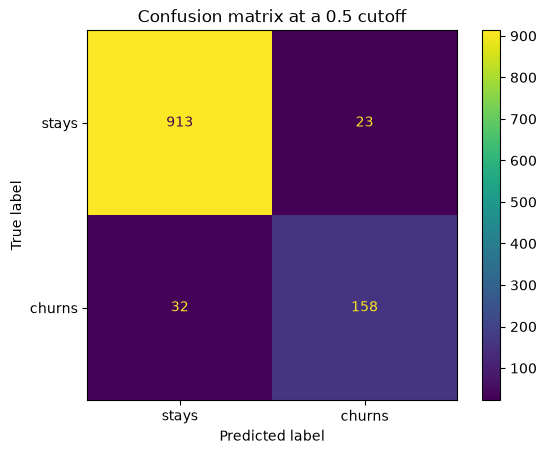

In [73]:
pred = (p_test >= 0.5).astype(int)
print(classification_report(y_test, pred))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["stays", "churns"])
plt.title("Confusion matrix at a 0.5 cutoff")
plt.show()

## Step 14. The proof chart

If the team contacts the top X% of customers by model score, what share of churners do they reach? The closer the blue line stays to the dashed "best possible" line, the better. The dotted line is a random list.

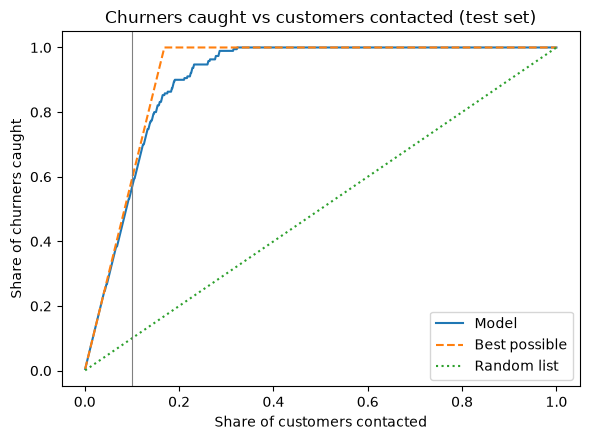

In [74]:
order = np.argsort(-p_test)
share_contacted = np.arange(1, len(y_arr) + 1) / len(y_arr)
share_caught = np.cumsum(y_arr[order]) / y_arr.sum()

plt.figure(figsize=(6, 4.5))
plt.plot(share_contacted, share_caught, label="Model")
plt.plot(share_contacted, np.minimum(share_contacted * len(y_arr) / y_arr.sum(), 1), "--", label="Best possible")
plt.plot(share_contacted, share_contacted, ":", label="Random list")
plt.axvline(0.10, color="grey", linewidth=0.8)
plt.xlabel("Share of customers contacted")
plt.ylabel("Share of churners caught")
plt.title("Churners caught vs customers contacted (test set)")
plt.legend()
plt.tight_layout()
os.makedirs("../images", exist_ok=True)
plt.savefig("../images/capture_curve.png", dpi=150)
plt.show()

## Step 15. Where does the model miss?

No model works equally well for everyone. Here I split the test customers by tenure and count how many churners the top-10% list finds in each group.

In [75]:
flagged = np.zeros(len(y_arr), dtype=bool)
flagged[order[:n_contact]] = True

tenure_test = pd.cut(X_test["Tenure"], [-1, 3, 6, 12, 24, 100],
                     labels=["0-3", "3-6", "6-12", "12-24", "24+"]).astype(object).fillna("missing")
table = pd.DataFrame({"tenure": tenure_test.values, "churned": y_arr, "flagged": flagged})

summary = table.groupby("tenure").agg(customers=("churned", "size"), churners=("churned", "sum"))
summary["churners_in_top10"] = table[table["churned"] == 1].groupby("tenure")["flagged"].sum()
summary.reindex(["missing", "0-3", "3-6", "6-12", "12-24", "24+"]).fillna(0).astype(int)

,customers,churners,churners_in_top10
tenure,,,
missing,67,29,14
0-3,301,108,82
3-6,123,13,2
6-12,270,19,1
12-24,266,21,8
24+,99,0,0


Some groups are small, so don't read too much into their percentages.

## Step 16. What does the model lean on?

Permutation importance shuffles one column at a time and measures how much the score drops. A big drop means the model leans on that column. I trust this more than the built-in importance of tree models, which can favour columns with many different values. It isn't perfect either. If two columns carry the same information, shuffling one can look harmless.

Tenure                  0.470
Complain                0.175
NumberOfAddress         0.137
CashbackAmount          0.086
WarehouseToHome         0.058
SatisfactionScore       0.058
DaySinceLastOrder       0.045
PreferredPaymentMode    0.044
dtype: float64


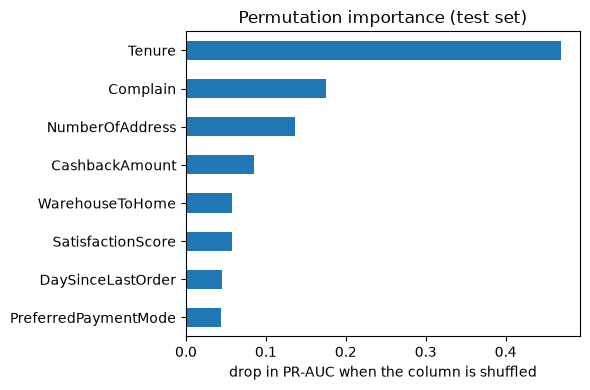

In [76]:
X_test_ready = prepare(X_test)
r = permutation_importance(final, X_test_ready, y_test, scoring="average_precision", n_repeats=10, random_state=0)
importance = pd.Series(r.importances_mean, index=X_test_ready.columns).sort_values(ascending=False)
print(importance.head(8).round(3))

importance.head(8)[::-1].plot.barh(figsize=(6, 4), title="Permutation importance (test set)")
plt.xlabel("drop in PR-AUC when the column is shuffled")
plt.tight_layout()
plt.show()

## Step 17. Save the model

The saved file holds the whole pipeline, preprocessing and model together. A raw customer row can go straight in.

If you turn capping on, the `Capper` class has to exist when you load the file. When I build the demo app, I'll move `Capper` and `add_features` into a separate `src/` file.

In [77]:
os.makedirs("../models", exist_ok=True)
joblib.dump(final, "../models/churn_pipeline.joblib", compress=3)

metrics = {
    "settings": {"new_feature": USE_NEW_FEATURE, "capping": USE_CAPPING, "smote": USE_SMOTE, "class_weight": USE_CLASS_WEIGHT},
    "best_params": best_params,
    "test_results": {k: round(float(v), 3) for k, v in exam.iloc[0].items() if k != "model"},
}
with open("../models/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print("model size (MB):", round(os.path.getsize("../models/churn_pipeline.joblib") / 1e6, 2))

model size (MB): 0.28


## Step 18. Score a few customers

A quick look at how a new customer row goes through the saved pipeline. These five customers may be part of the training data, so this only shows the mechanics. It isn't a test.

In [78]:
sample = df.sample(5, random_state=1)
sample_X = clean(sample.drop(columns=["CustomerID", "Churn"]))
sample["churn_risk"] = final.predict_proba(prepare(sample_X))[:, 1].round(3)
sample[["CustomerID", "Tenure", "Complain", "churn_risk", "Churn"]]

,CustomerID,Tenure,Complain,churn_risk,Churn
5240,55241,20.0,0,0.001,0
1660,51661,16.0,0,0.001,0
2106,52107,0.0,0,0.965,1
4581,54582,1.0,0,0.880,1
566,50567,13.0,1,0.006,0


## Limitations

- One public Kaggle dataset, and it may be an easy or synthetic one. A score this high probably won't hold on real company data.
- One train/test split and a small test set (190 churners).
- No dates, so I couldn't test on a later time period. That is how a real model gets used.
- I don't know when Tenure was measured relative to the churn event.

## What I'd do next

- Check that the predicted probabilities are honest (calibration).
- Turn the top-10% list into a money decision, using assumptions that are clearly labelled as assumptions.
- Plan for monitoring: watch for changes in the data, and retrain when real churn labels arrive.
- Move the code into `src/` and build a small Streamlit demo.